In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [7]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [8]:
df_alltruth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'pt!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [11]:
df_miss = applyCut(df_alltruth, 'pts<15 or bs==-9 or distance1>0.02 or distance2>0.02')

In [12]:
df_match = applyCut(df, 'pts>15 and distance1 < 0.02 and distance2 < 0.02')

In [27]:
df_alltruth.shape[0]

349521

In [28]:
df_alltruth = applyCut(df_alltruth, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [29]:
df_alltruth.shape[0]

349521

In [9]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [10]:
distance1 = []
distance2 = []
for i in range(0,df_alltruth.shape[0]):
    phi1small = min(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'])
    phi1large = max(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'])
    phi2small = min(df_alltruth.iloc[i]['phi2'], df_alltruth.iloc[i]['phi2s'])
    phi2large = max(df_alltruth.iloc[i]['phi2'], df_alltruth.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_alltruth.iloc[i]['y1']-df_alltruth.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_alltruth.iloc[i]['y2']-df_alltruth.iloc[i]['y2s'])**2))
df_alltruth['distance1'] = distance1
df_alltruth['distance2'] = distance2

In [13]:
w_array = np.unique(df_alltruth['w'])

In [14]:
df_match_pts_array = [ df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [15]:
rc_match_b_vs_pts_array = []
rc_err_match_b_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_b_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'b')[0])
    rc_err_match_b_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'b')[1])

In [16]:
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

In [22]:
x = [22.5, 27.5, 35]
xerr = [2.5, 2.5, 5]

In [17]:
df_match_pt_array = [ df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [18]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

In [20]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [21]:
alltruth_rc_match_b_vs_pt_array = []
alltruth_rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    alltruth_rc_match_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    alltruth_rc_err_match_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

In [22]:
df_miss_pt_array = [ df_miss[(df_miss.pt>20) & (df_miss.pt<25)],\
                       df_miss[(df_miss.pt>25) & (df_miss.pt<30)],\
                       df_miss[(df_miss.pt>30) & (df_miss.pt<40)] ]

In [23]:
miss_rc_match_b_vs_pt_array = []
miss_rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_miss_pt_array)):
    miss_rc_match_b_vs_pt_array.append(getRcAndErr(df_miss_pt_array[i], 'b')[0])
    miss_rc_err_match_b_vs_pt_array.append(getRcAndErr(df_miss_pt_array[i], 'b')[1])

In [25]:
x =  [22.5, 27.5, 35]
xerr = [2.5, 2.5, 5]

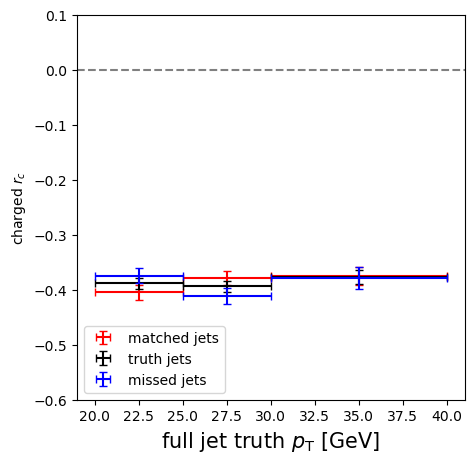

In [26]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(x, rc_match_b_vs_pt_array, xerr=xerr, yerr=rc_err_match_b_vs_pt_array, capsize=3, color='r', ls='none', label='matched jets')
#plt.errorbar(x, rc_match_bs_vs_pt_array, xerr=xerr, yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='r', ls='none', label='matched jets reco rc')
plt.errorbar(x, alltruth_rc_match_b_vs_pt_array, xerr=xerr, yerr=alltruth_rc_err_match_b_vs_pt_array, capsize=3, color='k', ls='none', label='truth jets')
plt.errorbar(x, miss_rc_match_b_vs_pt_array, xerr=xerr, yerr=miss_rc_err_match_b_vs_pt_array, capsize=3, color='b', ls='none', label='missed jets')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
#plt.title('Matching cut: reco pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [25]:
rcs_00 = getRcs(applyCut(df_match,'15<pts<20'))
rcs_err_00 = getRcsErr(applyCut(df_match,'15<pts<20'))

In [26]:
rcs_0 = getRcs(applyCut(df_match,'20<pts<25'))
rcs_err_0 = getRcsErr(applyCut(df_match,'20<pts<25'))

In [27]:
rcs_1 = getRcs(applyCut(df_match,'25<pts<30'))
rcs_err_1 = getRcsErr(applyCut(df_match,'25<pts<30'))

In [28]:
rcs_2 = getRcs(applyCut(df_match,'30<pts<40'))
rcs_err_2 = getRcsErr(applyCut(df_match,'30<pts<40'))

Text(0.5, 1.0, 'Matching cut: reco pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

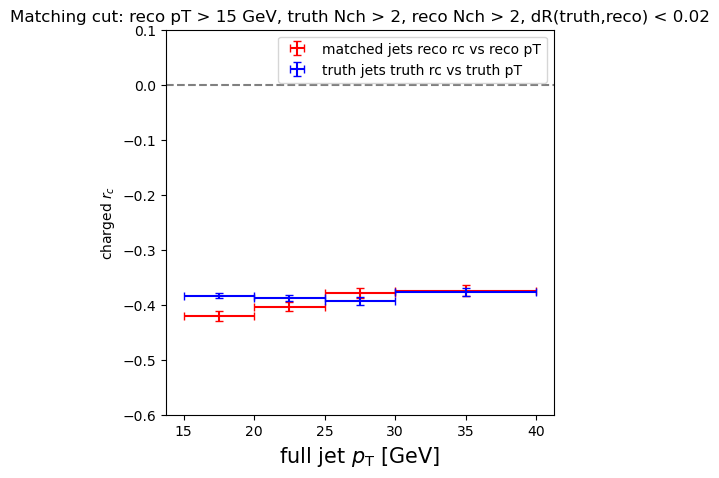

In [50]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='r', ls='none', label='matched jets reco rc vs reco pT')
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00_alltruth, rc_0_alltruth, rc_1_alltruth, rc_2_alltruth], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00_alltruth, rc_err_0_alltruth, rc_err_1_alltruth, rc_err_2_alltruth], capsize=3, color='b', ls='none', label='truth jets truth rc vs truth pT')
#plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00_miss, rc_0_miss, rc_1_miss, rc_2_miss], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00_miss, rc_err_0_miss, rc_err_1_miss, rc_err_2_miss], capsize=3, color='orange', ls='none', label='missed jets truth rc')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: reco pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [30]:
df_match_20 = applyCut(df_match, '20 < pt < 25')
df_alltruth_20 = applyCut(df_alltruth, '20 < pt < 25')
df_miss_20 = applyCut(df_miss, '20 < pt < 25')

In [57]:
ob = 'b'
range_low = -1.
range_high = 1.2
bins = 5

In [58]:
y_match_tru,yerr_match_tru,x = calc_hist(df_match_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'])
y_alltruth_tru,yerr_alltruth_tru,x = calc_hist(df_alltruth_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_20['w'])
y_miss_tru,yerr_miss_tru,x = calc_hist(df_miss_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_20['w'])

([], [])

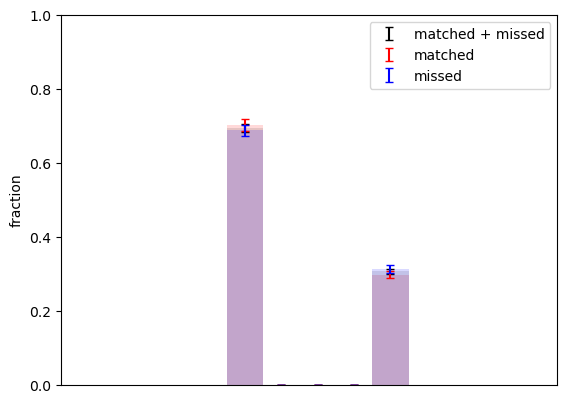

In [62]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_match_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w']/sum(df_match_20['w']), color='r', alpha=0.15)
plt.hist(df_alltruth_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_20['w']/sum(df_alltruth_20['w']), color='k', alpha=0.1)
plt.hist(df_miss_20[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_20['w']/sum(df_miss_20['w']), color='b', alpha=0.15)
plt.errorbar(x, y_alltruth_tru/sum(y_alltruth_tru), yerr=yerr_alltruth_tru/sum(y_alltruth_tru), capsize=3, color='k', label='matched + missed', ls='none')
plt.errorbar(x, y_match_tru/sum(y_match_tru), yerr=yerr_match_tru/sum(y_match_tru), capsize=3, color='r', label='matched', ls='none')
plt.errorbar(x, y_miss_tru/sum(y_miss_tru), yerr=yerr_miss_tru/sum(y_miss_tru), capsize=3, color='b', label='missed', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [63]:
df_match_25 = applyCut(df_match, '25 < pt < 30')
df_alltruth_25 = applyCut(df_alltruth, '25 < pt < 30')
df_miss_25 = applyCut(df_miss, '25 < pt < 30')

In [64]:
y_match_tru,yerr_match_tru,x = calc_hist(df_match_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w'])
y_alltruth_tru,yerr_alltruth_tru,x = calc_hist(df_alltruth_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_25['w'])
y_miss_tru,yerr_miss_tru,x = calc_hist(df_miss_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_25['w'])

([], [])

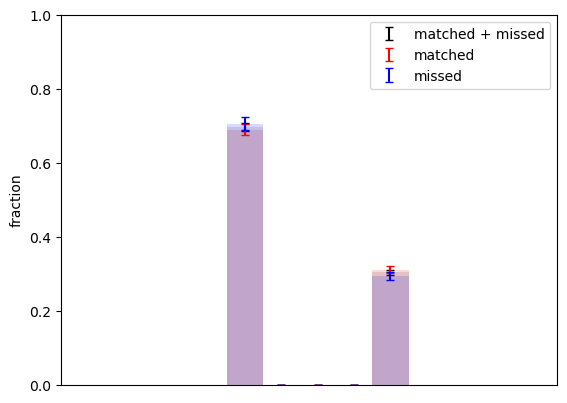

In [65]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_match_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w']/sum(df_match_25['w']), color='r', alpha=0.15)
plt.hist(df_alltruth_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_25['w']/sum(df_alltruth_25['w']), color='k', alpha=0.1)
plt.hist(df_miss_25[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_25['w']/sum(df_miss_25['w']), color='b', alpha=0.15)
plt.errorbar(x, y_alltruth_tru/sum(y_alltruth_tru), yerr=yerr_alltruth_tru/sum(y_alltruth_tru), capsize=3, color='k', label='matched + missed', ls='none')
plt.errorbar(x, y_match_tru/sum(y_match_tru), yerr=yerr_match_tru/sum(y_match_tru), capsize=3, color='r', label='matched', ls='none')
plt.errorbar(x, y_miss_tru/sum(y_miss_tru), yerr=yerr_miss_tru/sum(y_miss_tru), capsize=3, color='b', label='missed', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

In [66]:
df_match_30 = applyCut(df_match, '30 < pt < 40')
df_alltruth_30 = applyCut(df_alltruth, '30 < pt < 40')
df_miss_30 = applyCut(df_miss, '30 < pt < 40')

In [67]:
y_match_tru,yerr_match_tru,x = calc_hist(df_match_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w'])
y_alltruth_tru,yerr_alltruth_tru,x = calc_hist(df_alltruth_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_30['w'])
y_miss_tru,yerr_miss_tru,x = calc_hist(df_miss_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_30['w'])

([], [])

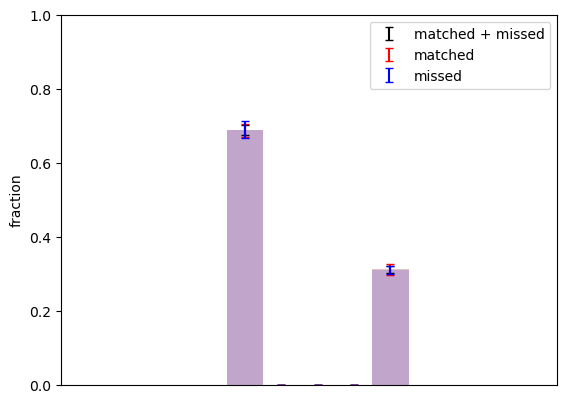

In [68]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.hist(df_match_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w']/sum(df_match_30['w']), color='r', alpha=0.15)
plt.hist(df_alltruth_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_alltruth_30['w']/sum(df_alltruth_30['w']), color='k', alpha=0.1)
plt.hist(df_miss_30[ob], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_miss_30['w']/sum(df_miss_30['w']), color='b', alpha=0.15)
plt.errorbar(x, y_alltruth_tru/sum(y_alltruth_tru), yerr=yerr_alltruth_tru/sum(y_alltruth_tru), capsize=3, color='k', label='matched + missed', ls='none')
plt.errorbar(x, y_match_tru/sum(y_match_tru), yerr=yerr_match_tru/sum(y_match_tru), capsize=3, color='r', label='matched', ls='none')
plt.errorbar(x, y_miss_tru/sum(y_miss_tru), yerr=yerr_miss_tru/sum(y_miss_tru), capsize=3, color='b', label='missed', ls='none')
plt.legend()
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-3,3)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])